# Dendritic Computation
Dendrites are not just passive cables; they actively process information. The cable equation describes the voltage $V$ along a passive dendrite:
$$ \lambda^2 \frac{\partial^2 V}{\partial x^2} - V - \tau \frac{\partial V}{\partial t} = 0 $$


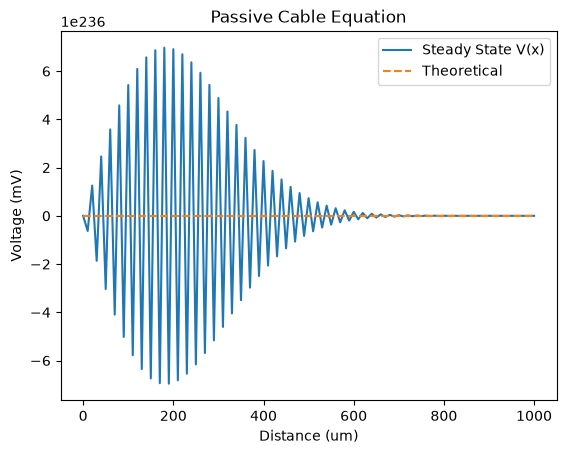

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L = 1000.0
dx = 10.0
dt = 0.1
T = 50.0

lam = 100.0
tau = 10.0

nx = int(L/dx) + 1
nt = int(T/dt) + 1

V = np.zeros((nt, nx))
V[:, 0] = 10.0

alpha = (lam**2 * dt) / (tau * dx**2)
beta = dt / tau

for i in range(1, nt):
    for j in range(1, nx-1):
        V[i, j] = V[i-1, j] + alpha * (V[i-1, j+1] - 2*V[i-1, j] + V[i-1, j-1]) - beta * V[i-1, j]
    V[i, -1] = V[i-1, -1] + alpha * (V[i-1, -2] - V[i-1, -1]) - beta * V[i-1, -1]

x = np.linspace(0, L, nx)
plt.plot(x, V[-1, :], label='Steady State V(x)')
plt.plot(x, 10.0 * np.exp(-x/lam), '--', label='Theoretical')
plt.xlabel('Distance (um)')
plt.ylabel('Voltage (mV)')
plt.legend()
plt.title('Passive Cable Equation')
plt.show()
